Saving dog.jpeg to dog.jpeg
IMAGE SMOOTHING
----------------
Enter filter size (odd number, e.g. 3, 5, 7): 3
Enter padding method (zero / replicate): replicate
Enter sigma for Gaussian filter: 1

1. Averaging Filter
2. Weighted Filter
3. Gaussian Filter
4. All Filters
Enter your choice: 4


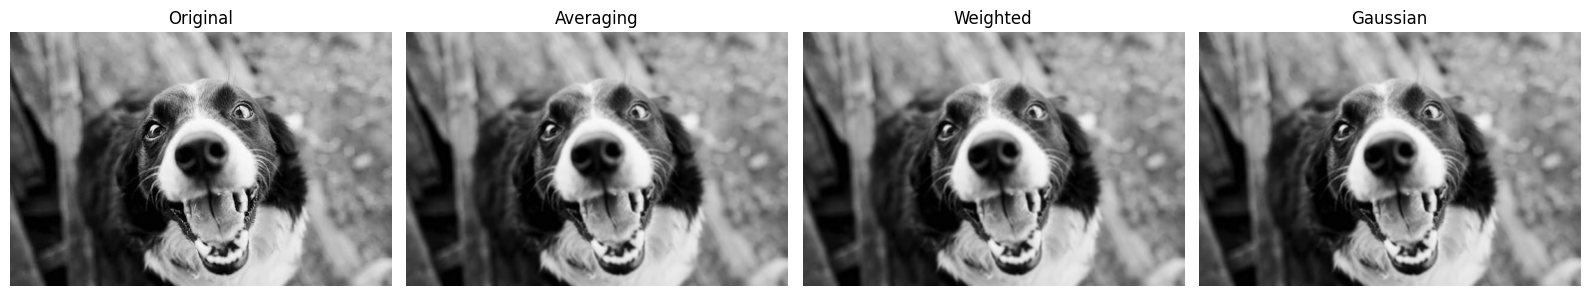

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from PIL import Image


uploaded = files.upload()
filename = list(uploaded.keys())[0]
img = np.array(Image.open(filename).convert('RGB'))


def pad_image(img, pad, method):
    if method == "zero":
        return np.pad(img, ((pad, pad), (pad, pad), (0, 0)),
                      mode='constant', constant_values=0)
    elif method == "replicate":
        return np.pad(img, ((pad, pad), (pad, pad), (0, 0)),
                      mode='edge')
    else:
        raise ValueError("Use 'zero' or 'replicate' for padding.")


def apply_filter(img, kernel, padding_method):
    k = kernel.shape[0]
    pad = k // 2
    padded = pad_image(img, pad, padding_method)

    h, w, ch = img.shape
    output = np.zeros((h, w, ch), dtype=np.float64)

    for i in range(h):
        for j in range(w):
            region = padded[i:i+k, j:j+k]

            for c in range(ch):
                output[i, j, c] = np.sum(region[:, :, c] * kernel)

    return np.clip(output, 0, 255).astype(np.uint8)


def averaging_filter(img, size, padding):
    kernel = np.ones((size, size), dtype=np.float64) / (size * size)
    return apply_filter(img, kernel, padding)


def weighted_filter(img, size, padding):
    center = size // 2
    kernel = np.zeros((size, size), dtype=np.float64)

    for i in range(size):
        for j in range(size):
            x = i - center
            y = j - center
            kernel[i, j] = max(abs(x), abs(y))


    if np.sum(kernel) != 0:
        kernel = kernel / np.sum(kernel)

    return apply_filter(img, kernel, padding)


def gaussian_filter(img, size, sigma, padding):
    center = size // 2
    kernel = np.zeros((size, size), dtype=np.float64)

    for i in range(size):
        for j in range(size):
            x = i - center
            y = j - center

            kernel[i, j] = (1 / (2 * np.pi * sigma**2)) * \
                           np.exp(-(x**2 + y**2) / (2 * sigma**2))


    kernel = kernel / np.sum(kernel)

    return apply_filter(img, kernel, padding)


print("IMAGE SMOOTHING")
print("----------------")

size = int(input("Enter filter size (odd number, e.g. 3, 5, 7): "))

if size % 2 == 0:
    raise ValueError("Filter size must be odd.")

padding = input("Enter padding method (zero / replicate): ").lower()

sigma = float(input("Enter sigma for Gaussian filter: "))

print("\n1. Averaging Filter")
print("2. Weighted Filter")
print("3. Gaussian Filter")
print("4. All Filters")

choice = int(input("Enter your choice: "))


if choice == 1:
    result = averaging_filter(img, size, padding)

    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(result)
    plt.title("Averaging Filter")
    plt.axis("off")
    plt.show()

elif choice == 2:
    result = weighted_filter(img, size, padding)

    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(result)
    plt.title("Weighted Filter")
    plt.axis("off")
    plt.show()

elif choice == 3:
    result = gaussian_filter(img, size, sigma, padding)

    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(result)
    plt.title("Gaussian Filter")
    plt.axis("off")
    plt.show()

elif choice == 4:
    avg = averaging_filter(img, size, padding)
    weighted = weighted_filter(img, size, padding)
    gaussian = gaussian_filter(img, size, sigma, padding)

    plt.figure(figsize=(16, 5))

    plt.subplot(1, 4, 1)
    plt.imshow(img)
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1, 4, 2)
    plt.imshow(avg)
    plt.title("Averaging")
    plt.axis("off")

    plt.subplot(1, 4, 3)
    plt.imshow(weighted)
    plt.title("Weighted")
    plt.axis("off")

    plt.subplot(1, 4, 4)
    plt.imshow(gaussian)
    plt.title("Gaussian")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

else:
    print("Invalid choice.")